# Import modules

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.utils import Bunch
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

# Define a seed 

In [2]:
SEED: int = 42069

# Define path to data from current directory 

In [3]:
euro_test_path: str = "../data/EuroTest.csv"
euro_training_path: str = "../data/EuroTraining.csv"
handball_long_path: str = "../data/handball_long.csv"
handball_wide_path: str = "../data/handball_wide.csv"
tennis_path: str = "../data/SlamsData.csv"

# Load data in pandas DataFrame 

In [4]:
euro_test_df: pd.DataFrame = pd.read_csv(euro_test_path)
euro_training_df: pd.DataFrame = pd.read_csv(euro_training_path)
handball_long_df: pd.DataFrame = pd.read_csv(handball_long_path)
handball_wide_df: pd.DataFrame = pd.read_csv(handball_wide_path)
tennis_df: pd.DataFrame = pd.read_csv(tennis_path)

# Define features

In [5]:
handball_features: list[str] = [
    "bet.probs.diff",
    "season"
]
hand_feat_df: pd.DataFrame = handball_wide_df[handball_features]

euro_features: list[str] = [
    "GroupStage",
    "GDP",
    "MarketValue", 
    "FifaRank", 
    "UefaPoints",
    "CLPlayers"
]
euro_feat_df: pd.DataFrame = euro_training_df[euro_features]
euro_feat_test_df: pd.DataFrame = euro_test_df[euro_features]

tennis_features: list[str] = [
    "rank", 
    "points", 
    "elo", 
    "age.30"
]
tennis_feat_df: pd.DataFrame = tennis_df[tennis_features]

# Define predictors

In [6]:
handball_response: str = "scorediff"
hand_res: pd.Series = handball_wide_df[handball_response]

euro_response: str = "Goals"
euro_res: pd.Series = euro_training_df[euro_response]

tennis_response: str = "win"
tennis_res: pd.Series = tennis_df[tennis_response]

# define regression trees for handball/euro and classification tree for tennis

In [7]:
params_dict: dict[str, int | float] = {
    "random_state": SEED,
    "min_samples_split": 20,
    "max_depth": 30,
    "min_samples_leaf": round(20/3),
    "ccp_alpha": 0.01,
}
handball_tree: DecisionTreeRegressor = DecisionTreeRegressor(
    **params_dict
)
euro_tree: DecisionTreeRegressor = DecisionTreeRegressor(
    **params_dict
)

tennis_tree: DecisionTreeClassifier = DecisionTreeClassifier(
    **params_dict
)

# Fit the trees 

In [8]:
handball_tree.fit(hand_feat_df, hand_res) 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.01
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, t

In [9]:
euro_tree.fit(euro_feat_df, euro_res)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.01
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, t

In [10]:
tennis_tree.fit(tennis_feat_df, tennis_res)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.01
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_i

In [11]:
tennis_tree.get_n_leaves()

np.int64(4)

# Plot trees

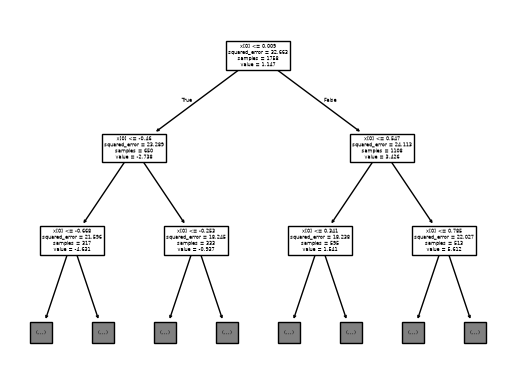

In [12]:
plot_tree(handball_tree, max_depth=2)
plt.show()

# Predict handball(scorediff), euro(Goals), tennis(win)

In [13]:
handball_pred: np.ndarray = handball_tree.predict(hand_feat_df)
euro_pred: np.ndarray = euro_tree.predict(euro_feat_df)
tennis_pred: np.ndarray = tennis_tree.predict(tennis_feat_df)

# calc diff of response column and correct tennis predictions

In [14]:
handball_mae: float = mean_absolute_error(hand_res, handball_pred)
handball_rmse: float = root_mean_squared_error(hand_res, handball_pred)

euro_mae: float = mean_absolute_error(euro_res, euro_pred)
euro_rmse: float = root_mean_squared_error(euro_res, euro_pred)

tennis_ratio: np.float64 = (tennis_pred == tennis_res).sum() / tennis_df.shape[0]

In [15]:
print(handball_mae, handball_rmse)
print(euro_mae, euro_rmse)
print(tennis_ratio)

3.047517748011684 3.8987793837144324
0.7531839800336969 0.9410013789233508
0.7504531722054381


identify the matches with the largest overestimation and underestimation. For the tennis data,
identify those predictions with the most extreme predicted winning probabilities. Discuss possible
reasons based on the data

In [16]:
hand_10_largest_diff_idx: pd.Series = (handball_pred - hand_res).abs().nlargest(10)
handball_wide_df.loc[hand_10_largest_diff_idx.index]

,matchid,hometeam,awayteam,season,homegoals,awaygoals,scorediff,bet.probs.diff
1310,1324,HSG Wetzlar,Hannover-Burgdorf,2021,38,16,22,0.220076
1415,1433,TBV Lemgo Lippe,SC Magdeburg,2021,25,44,-19,-0.547495
160,161,Rhein-Neckar Löwen,TBV Lemgo Lippe,2017,38,17,21,0.833881
1407,1424,TBV Lemgo Lippe,GWD Minden,2021,20,32,-12,0.570115
984,995,HSG Wetzlar,Eulen Ludwigshafen,2020,29,11,18,0.739844
560,562,VfL Gummersbach,Rhein-Neckar Löwen,2018,28,23,5,-0.834297
1725,1759,SG Flensburg-Handewitt,THW Kiel,2022,36,23,13,-0.058331
651,653,HBW Balingen-Weilstetten,MT Melsungen,2019,35,23,12,-0.458439
1067,1078,SC Magdeburg,HSC 2000 Coburg,2020,43,22,21,0.850185
1065,1076,SC Magdeburg,HBW Balingen-Weilstetten,2020,26,28,-2,0.852923


In [17]:
euro_10_largest_diff: pd.Series = (euro_pred - euro_res).abs().nlargest(10)
idx: pd.Index = euro_10_largest_diff.index.append(
    euro_10_largest_diff.index.map(lambda x: x + pow(-1, x%2))
).sort_values()
euro_training_df.iloc[idx]

,Goals,Team,Opponent,Year,GroupStage,GDP,MarketValue,FifaRank,UefaPoints,CLPlayers
26,3,Netherlands,Italy,2008,1,0.317074,-0.413355,7,-25105,1.000000
27,0,Italy,Netherlands,2008,1,-0.317074,0.413355,-7,25105,-1.000000
30,4,Netherlands,France,2008,1,0.182522,-0.332220,3,-14245,-5.000000
31,1,France,Netherlands,2008,1,-0.182522,0.332220,-3,14245,5.000000
52,1,Netherlands,Russia,2008,0,1.509778,0.613257,-15,14165,2.000000
53,3,Russia,Netherlands,2008,0,-1.509778,-0.613257,15,-14165,-2.000000
82,2,Croatia,England,2004,1,-1.381492,-1.466337,13,-44778,-3.000000
83,4,England,Croatia,2004,1,1.381492,1.466337,-13,44778,3.000000
184,4,Spain,Italy,2012,0,-0.113985,0.798857,-11,35274,14.000000
185,0,Italy,Spain,2012,0,0.113985,-0.798857,11,-35274,-14.000000


In [18]:
# tennis
tennis_pred_prob: np.ndarray = tennis_tree.predict_proba(tennis_feat_df)[:,1]
tennis_10_biggest_diff: pd.Series = (tennis_pred_prob - tennis_res).abs().nlargest(10)

tennis_df.loc[tennis_10_biggest_diff.index]

,player.1,player.2,year,tournament,surface,win,sets.1,sets.2,rank,points,elo,prob,age.30,AvgProb.1,AvgProb.2,B365.1,B365.2
5,Aslan Karatsev,Adrian Mannarino,2022,Australian Open,Hard,0,1,3,-54,1674,209.079639,0.527619,-1.946545,0.763810,0.236190,1.25,4.00
72,Milos Raonic,Albert Ramos,2016,French Open,Clay,0,0,3,-46,1932,315.516111,0.585366,2.942586,0.792683,0.207317,1.20,4.50
104,John Isner,Alejandro Falla,2012,Wimbledon,Grass,0,2,3,-63,1991,255.322681,0.677143,1.445714,0.838571,0.161429,1.12,6.00
107,Mardy Fish,Alejandro Falla,2012,Australian Open,Hard,0,0,3,-63,2269,288.040459,0.727840,-1.712583,0.863920,0.136080,1.08,8.00
113,Fabio Fognini,Alejandro Gonzalez,2015,Australian Open,Hard,0,1,3,-89,1271,200.663963,0.401330,-1.709589,0.700665,0.299335,1.36,3.00
127,Benoit Paire,Alex Bogomolov Jr,2013,US Open,Hard,0,2,3,-45,719,172.397995,0.274510,5.339726,0.637255,0.362745,1.40,2.62
130,Juan Ignacio Chela,Alex Bogomolov Jr,2011,Wimbledon,Grass,0,0,3,-52,814,199.684239,0.040000,-0.024658,0.520000,0.480000,1.72,2.00
134,Filip Krajinovic,Alex Bolt,2021,Wimbledon,Grass,0,0,3,-105,997,268.617037,-0.108808,-0.854795,0.445596,0.554404,2.37,1.57
351,Tomas Berdych,Alexandr Dolgopolov,2017,US Open,Hard,0,1,3,-46,1559,238.092680,0.532075,0.769444,0.766038,0.233962,1.25,4.00
360,David Goffin,Alexei Popyrin,2021,Australian Open,Hard,0,2,3,-98,1957,208.085004,0.353349,-8.309589,0.676674,0.323326,1.40,3.00


In [19]:
tennis_df.head()

,player.1,player.2,year,tournament,surface,win,sets.1,sets.2,rank,points,elo,prob,age.30,AvgProb.1,AvgProb.2,B365.1,B365.2
0,Adam Pavlasek,Ernesto Escobedo,2017,Wimbledon,Grass,1,3,1,62,-275,-149.309441,-0.339535,-1.736986,0.330233,0.669767,2.75,1.44
1,Mirza Basic,Adam Pavlasek,2018,French Open,Clay,0,1,3,-104,400,67.578613,-0.280193,-3.241096,0.359903,0.640097,2.62,1.50
2,Roberto Carballes Baena,Adam Pavlasek,2016,French Open,Clay,0,2,3,-18,81,47.921054,0.178571,-1.545812,0.589286,0.410714,1.53,2.37
3,Adam Walton,Federico Coria,2024,Wimbledon,Grass,1,3,0,29,-169,-20.076166,0.521073,2.478142,0.760536,0.239464,1.25,4.00
4,Alexander Shevchenko,Adrian Mannarino,2023,Wimbledon,Grass,0,0,3,62,-489,-55.552644,-0.569395,2.389041,0.215302,0.784698,4.50,1.20


# handball create scatter predicted / actual scorediff with bisect line

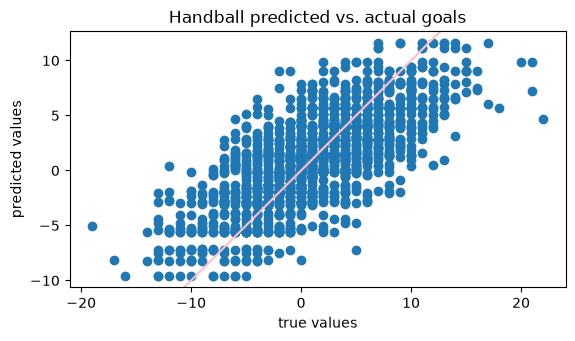

In [20]:
fig, ax = plt.subplots()
ax.scatter(hand_res, handball_pred)
ax.set_title("Handball predicted vs. actual goals")
ax.set_xlabel("true values")
ax.set_ylabel("predicted values")
ax.axline((0,0), slope=1, linestyle="-", color="pink")
ax.set_aspect("equal", adjustable="box")
plt.show()

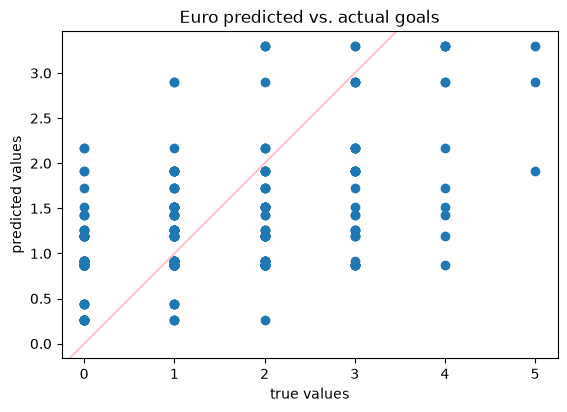

In [21]:
fig, ax = plt.subplots()
ax.scatter(euro_res, euro_pred)
ax.set_title("Euro predicted vs. actual goals")
ax.set_xlabel("true values")
ax.set_ylabel("predicted values")
ax.axline((0,0), slope=1, linestyle="-", color="pink")
ax.set_aspect("equal", adjustable="box")
plt.show()

<Axes: xlabel='win', ylabel='pred_proba'>

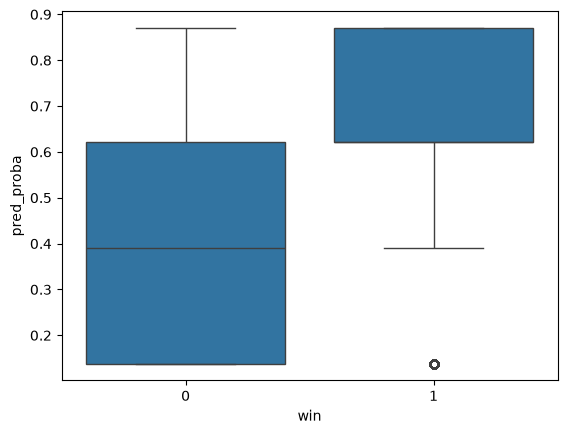

In [22]:
tennis_df["pred_proba"] = tennis_pred_prob
sns.boxplot(x="win", y="pred_proba", data=tennis_df)

In [38]:
tennis_df.groupby("win")["pred_proba"].median()

win
0    0.391003
1    0.620647
Name: pred_proba, dtype: float64

# Task 2 

# examine feature importance measure for euro tree

In [24]:
feat_importance: list[tuple[str, float]] = list(zip(euro_features, euro_tree.feature_importances_))
feat_importance

[('GroupStage', np.float64(0.0)),
 ('GDP', np.float64(0.16772453033049772)),
 ('MarketValue', np.float64(0.5588293612027121)),
 ('FifaRank', np.float64(0.21702566127751094)),
 ('UefaPoints', np.float64(0.037298316434442015)),
 ('CLPlayers', np.float64(0.019122130754837232))]

In [25]:
perm_importance: Bunch = permutation_importance(
    euro_tree,
    euro_feat_df,
    euro_res,
    scoring="neg_mean_squared_error",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1
)
importance_df: pd.DataFrame = pd.DataFrame({
    "importances": perm_importance.importances_mean,
    "std": perm_importance.importances_std,
},
    index= euro_features,
                                          )

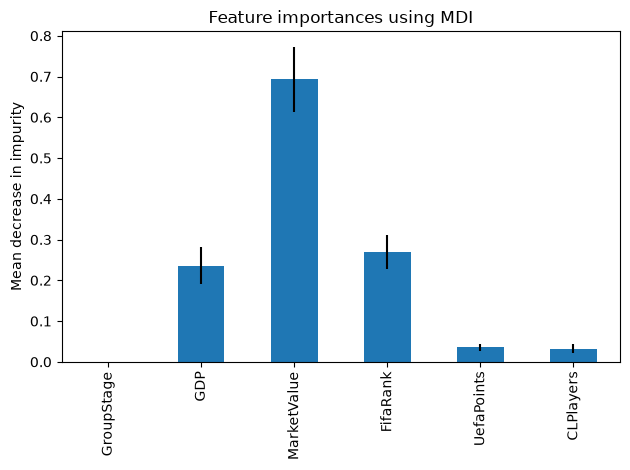

In [26]:
fig, ax = plt.subplots()
importance_df["importances"].plot.bar(
    ax=ax,
    yerr=importance_df["std"]
)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

# Predict number of goals for euro test and compute metrics

In [27]:
euro_feat_test_df: pd.DataFrame = euro_test_df[euro_features]
euro_test_res: pd.Series = euro_test_df[euro_response]
euro_test_pred: np.ndarray = euro_tree.predict(euro_feat_test_df)
euro_test_mae: float = mean_absolute_error(euro_test_res, euro_test_pred)
euro_test_rmse: float = root_mean_squared_error(euro_test_res, euro_test_pred)

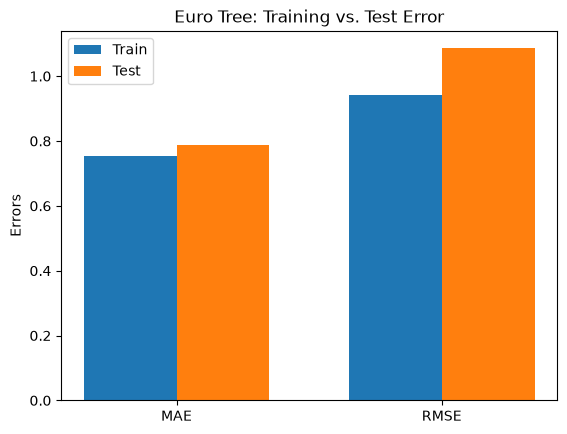

In [28]:
stats: list[str] = ["MAE", "RMSE"]
euro_comparison: dict[str, list[float]] = {
    "train": [euro_mae, euro_rmse],
    "test": [euro_test_mae, euro_test_rmse]
}
x: np.ndarray = np.arange(2)
width: float = .35

fig, ax = plt.subplots()

ax.bar(x - width / 2, euro_comparison["train"], width, label="Train")
ax.bar(x + width / 2, euro_comparison["test"], width, label="Test")

ax.set_xticks(x, stats)
ax.set_ylabel("Errors")
ax.set_title("Euro Tree: Training vs. Test Error")
ax.legend()
plt.show()

# make a more appealing graph for presentation if this should be presented

# Perform grid search 

In [29]:
grid_params: dict[str, list[float | int]] = {
    "ccp_alpha": [0.0, 0.001, 0.005, 0.02, 0.05],
    "min_samples_split": [2, 5, 10, 20, 40],
    "max_depth": [1, 2, 3, 5, 7, 10, 15],
    "random_state": [SEED]
}
grid_result: list[dict[str, [DecisionTreeRegressor | float | int]]] = []
for i, g in enumerate(ParameterGrid(grid_params)):
    min_sample_leaf: int = round(g["min_samples_split"]/3)
    tmp: dict[str, [DecisionTreeRegressor | float]] = {}
    tmp_model: DecisionTreeRegressor = DecisionTreeRegressor(**g, min_samples_leaf=min_sample_leaf)
    tmp_model.fit(euro_feat_df, euro_res)
    tmp_train_pred: np.ndarray = tmp_model.predict(euro_feat_df)
    tmp_test_pred: np.ndarray = tmp_model.predict(euro_feat_test_df)
    tmp["idx"] = i
    tmp["model"] = tmp_model
    tmp["mae_train"] = mean_absolute_error(euro_res, tmp_train_pred)
    tmp["mae_test"] = mean_absolute_error(euro_test_res, tmp_test_pred)
    grid_result.append(tmp)

In [30]:
min_model_dict: dict[str, [DecisionTreeRegressor | float]] = min(grid_result, key=lambda x: x.get("mae_test"))
min_model_idx: int = min_model_dict["idx"]
min_model_dict["model"].get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': 3,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 2,
 'min_samples_split': 5,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42069,
 'splitter': 'best'}

In [31]:
max_model_dict: dict[str, [DecisionTreeRegressor | float]] = max(grid_result, key=lambda x: abs(x.get("mae_test")-x.get("mae_train")))
max_model_idx: int = max_model_dict["idx"]
max_model_dict["model"].get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': 15,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42069,
 'splitter': 'best'}

# Visualize the best tree as well as the most overfitting tree

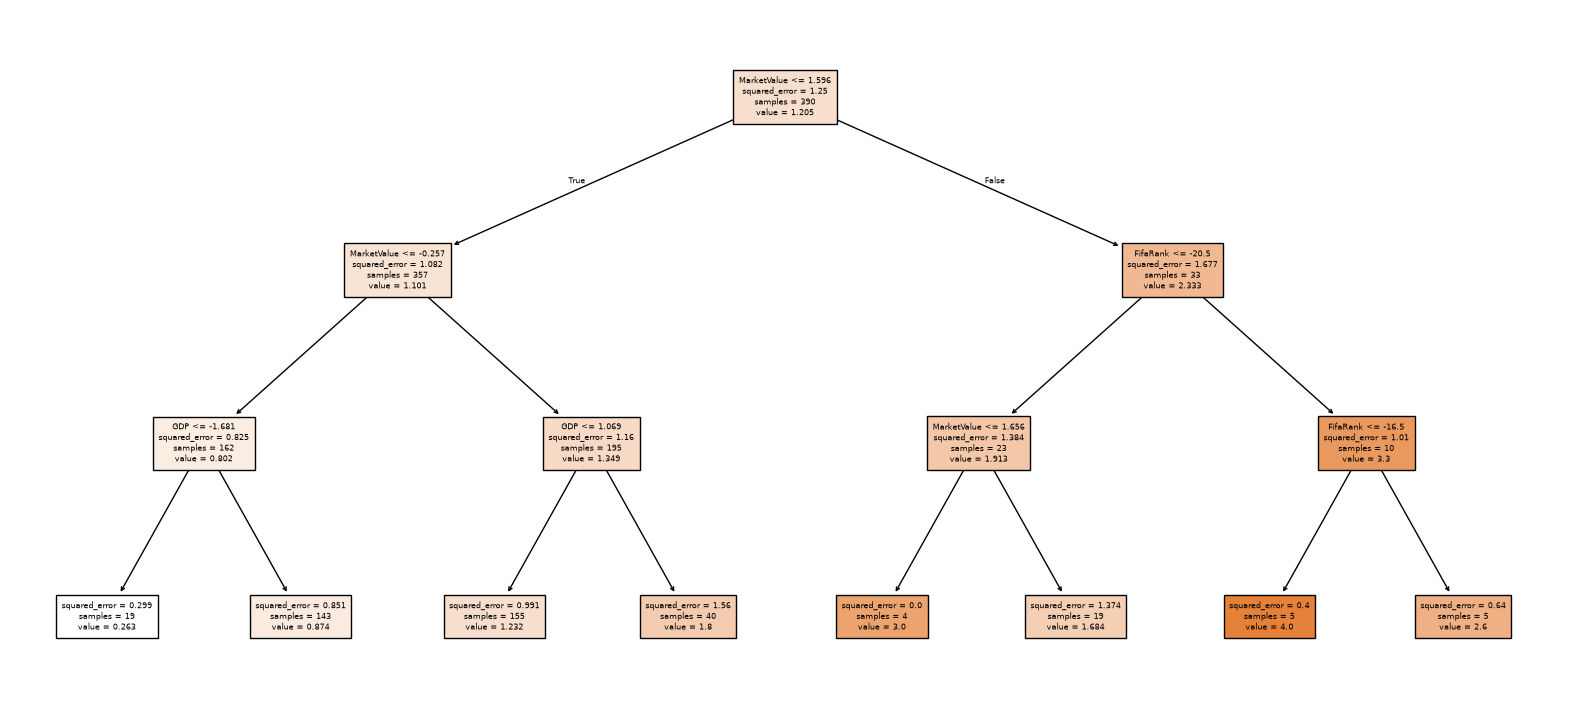

In [32]:
plt.figure(figsize=(20, 9))
plot_tree(min_model_dict["model"], feature_names=euro_features, filled=True, fontsize=6)
plt.show()

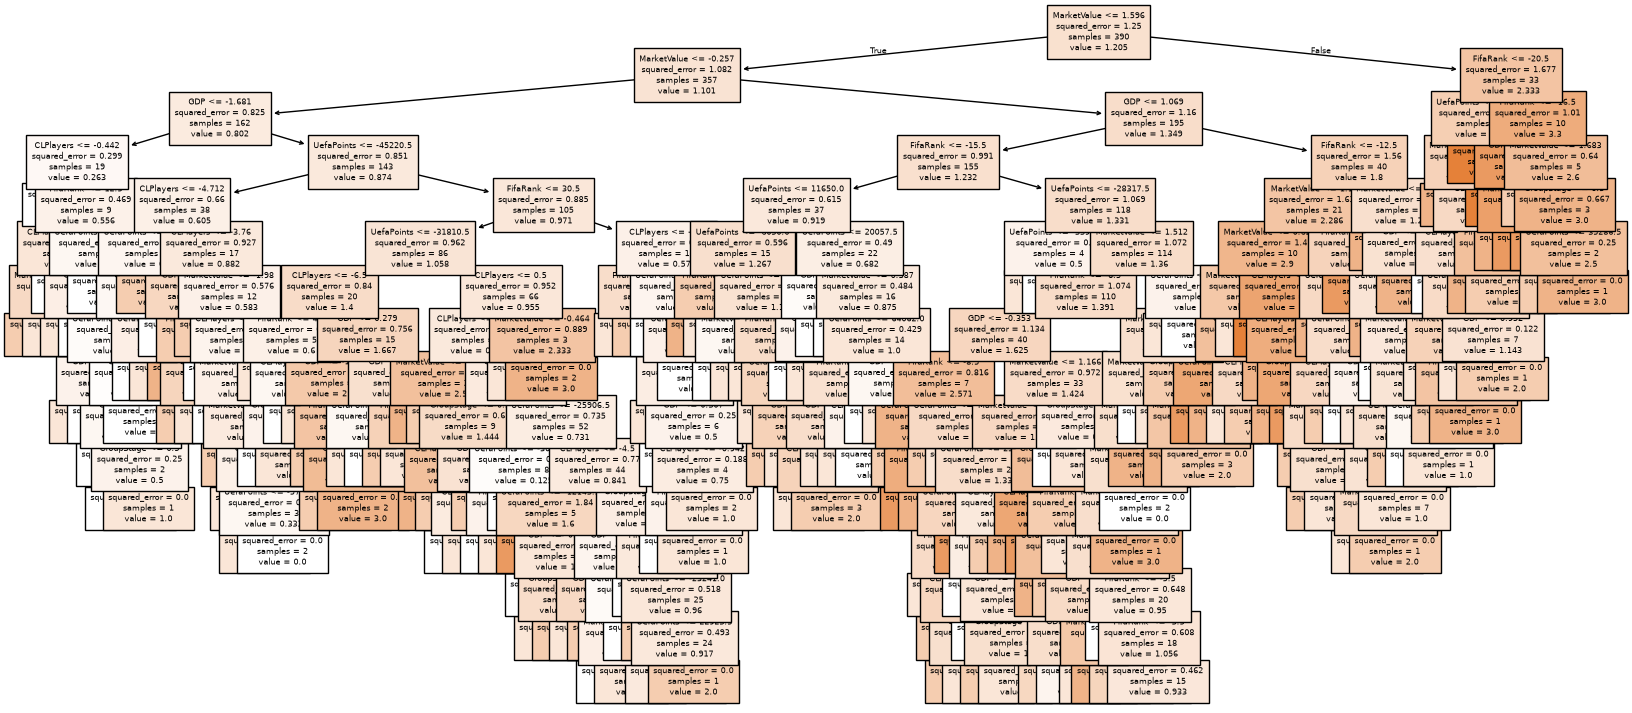

In [34]:
plt.figure(figsize=(20, 9))
plot_tree(max_model_dict["model"], feature_names=euro_features, filled=True, fontsize=6)
plt.show()

# Visualize how the training and test MAE change with increasing tree complexity.
with cp=0 and minsplit=2, minbucket=round(minsplit/3):=min_sample_leaves 